# EDA: CUB-200-2011 with captions (Task 1.1)

This notebook is a **supplement**. The analysis lives in `src/data/eda.py` and runs from the command line:

```bash
python -m src.data.eda --out outputs/eda                    # all steps
python -m src.data.eda --out outputs/eda --fetch-cub-meta   # also download the official CUB text files (boxes, split)
```

Here we load the results the script saved, show the key figures, and try two extra explorations that are not part of the script.
The written findings and recommendations are in `docs/eda_findings.md`.

In [1]:
import json
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":  # run from the repository root so the paths below work
    os.chdir("..")
warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars from the datasets library

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.data.eda import EDAContext, load_official_metadata, load_splits

%matplotlib inline

OUT = Path("outputs/eda")
summary = json.loads((OUT / "summary.json").read_text())
train, test = load_splits()
ctx = EDAContext(train=train, test=test, out=OUT, cub_meta=Path("data/CUB_200_2011"))
print(len(train), "train images,", len(test), "test images; summary steps:", list(summary))

5994 train images, 5794 test images; summary steps: ['inspect', 'classes', 'images', 'quality', 'captions', 'augment']


## 1-2. Inspection and class distribution

In [2]:
inspect = summary["inspect"]
official = inspect.get("official_metadata", {})
pd.DataFrame({
    "check": ["rows (train / test)", "classes", "duplicate ids", "file names in both splits",
              "label vs file-name mismatches", "split differs from official CUB", "label differs from official CUB"],
    "value": [f"{inspect['train']['num_rows']} / {inspect['test']['num_rows']}",
              summary["classes"]["num_classes"], inspect["duplicate_ids_within_split"],
              inspect["file_names_shared_by_train_and_test"], inspect["label_filename_mismatches"],
              official.get("split_differs_from_official", "n/a"), official.get("label_differs_from_official", "n/a")],
})

,check,value
0,rows (train / test),5994 / 5794
1,classes,200
2,duplicate ids,0
3,file names in both splits,0
4,label vs file-name mismatches,0
5,split differs from official CUB,0
6,label differs from official CUB,0


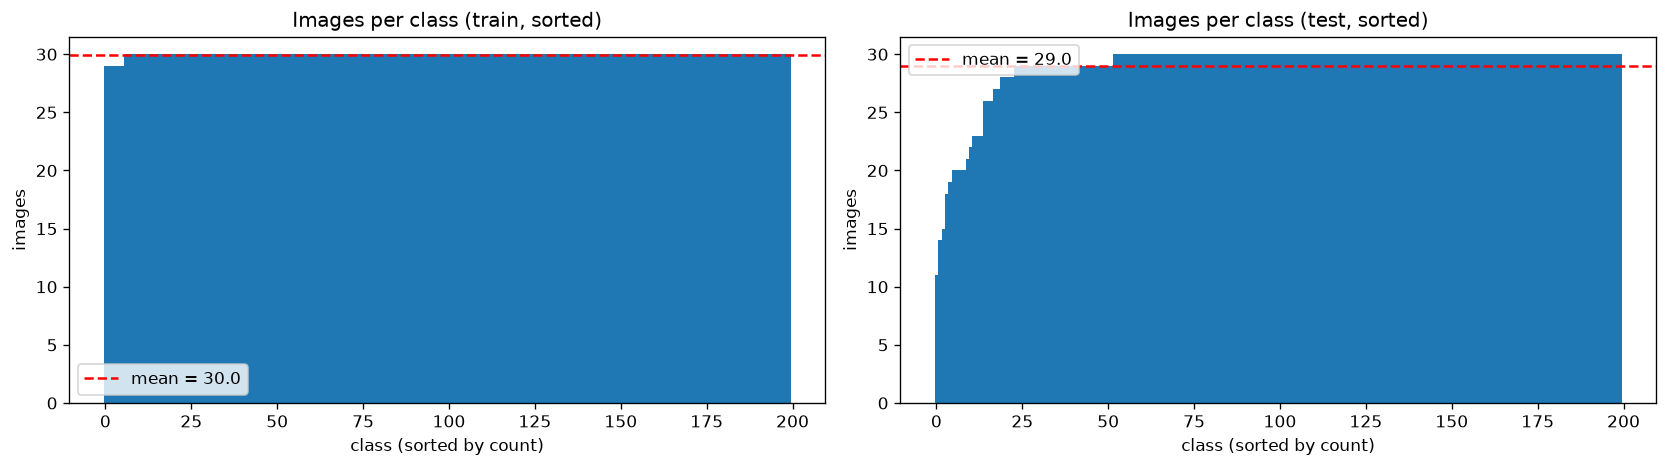

,train,test
min,29,11
max,30,30
mean,29.97,28.97
std,0.17,2.92
imbalance_ratio_max_over_min,1.03,2.73


In [3]:
display(Image(OUT / "figures/02_class_distribution.png", width=900))
pd.DataFrame({s: summary["classes"][s] for s in ("train", "test")}).drop("classes_with_zero_images")

## 3. Images: sizes, quality, normalization

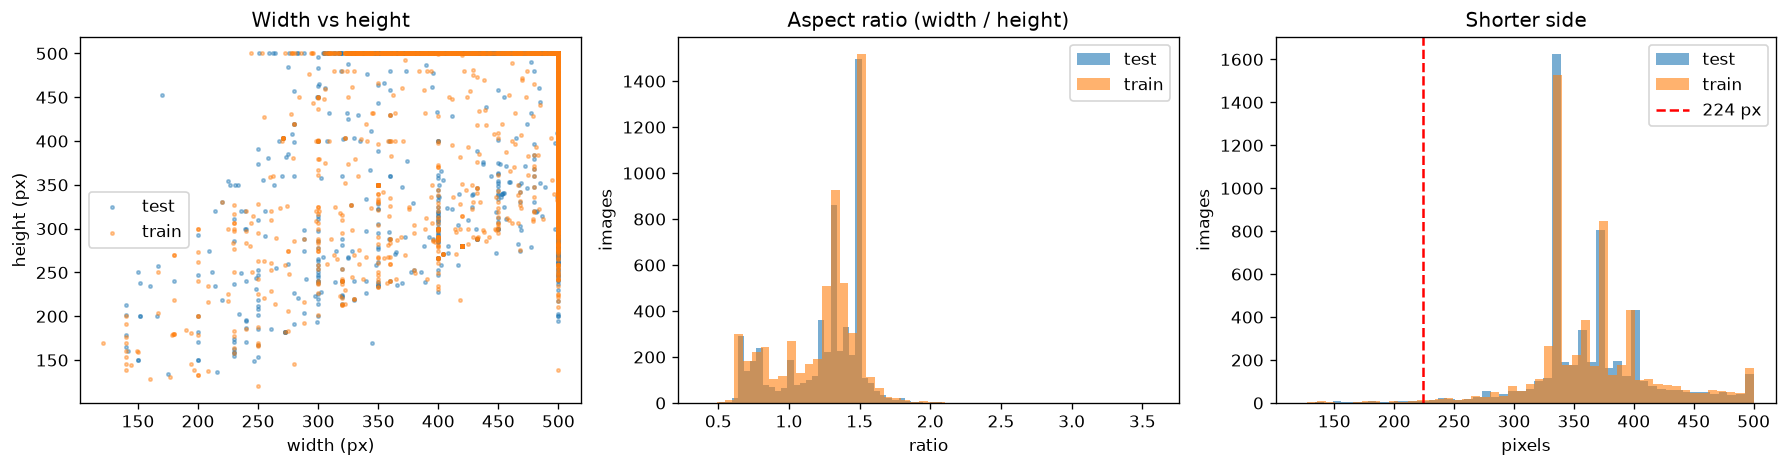

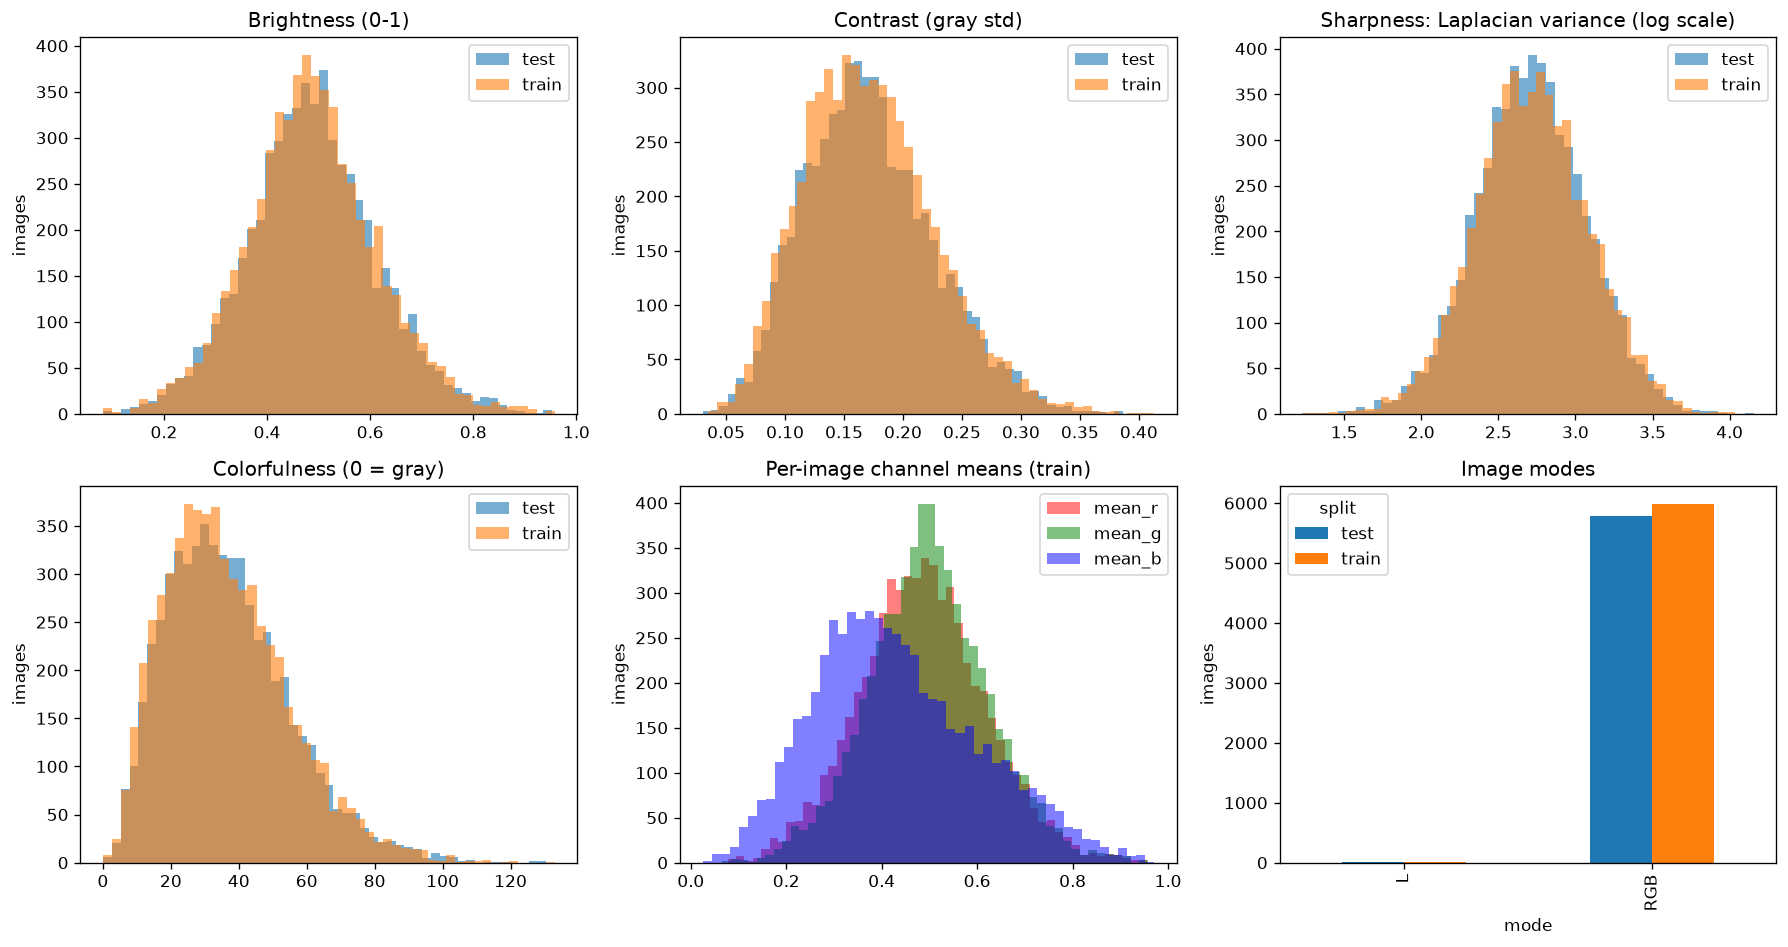

modes: {'test': {'RGB': 5790, 'L': 4}, 'train': {'RGB': 5990, 'L': 4}} | grayscale: {'test': 4, 'train': 5} | shorter side < 224: 148
train normalization: {'mean': [0.4856, 0.4994, 0.4324], 'std': [0.2272, 0.2226, 0.2613]}


In [4]:
display(Image(OUT / "figures/03_image_sizes.png", width=900))
display(Image(OUT / "figures/03_image_quality.png", width=900))
img = summary["images"]
print("modes:", img["modes"], "| grayscale:", img["n_grayscale"], "| shorter side < 224:", img["n_shorter_side_below_224"])
print("train normalization:", img["normalization_train"])

The example grids are large, so they are linked instead of embedded:
[least colorful](../outputs/eda/figures/03_examples_least_colorful.png),
[blurriest](../outputs/eda/figures/03_examples_blurriest.png),
[darkest](../outputs/eda/figures/03_examples_darkest.png),
[smallest](../outputs/eda/figures/03_examples_smallest.png),
[grayscale](../outputs/eda/figures/03_examples_grayscale.png).

## 4. Data quality: duplicates and leakage

In [5]:
near = pd.read_csv(OUT / "tables/near_duplicates.csv")
print({k: v for k, v in summary["quality"].items() if "pair" in k or "duplicate" in k or "drop" in k})
near[["split_a", "file_a", "split_b", "file_b", "hamming", "verdict", "note"]]

{'exact_duplicate_groups': 1, 'exact_duplicate_groups_across_train_test': 0, 'near_duplicate_pairs_by_threshold': {'2': 8, '4': 8, '6': 12}, 'near_duplicate_threshold_bits': 6, 'near_duplicate_pairs': 12, 'near_duplicate_pairs_across_train_test': 5, 'near_duplicate_pairs_with_different_labels': 4, 'near_duplicate_verdicts': {'duplicate': 9, 'false_positive': 3}, 'train_images_to_drop_for_leakage': 3}


,split_a,file_a,split_b,file_b,hamming,verdict,note
0,train,Laysan_Albatross_0065_809.jpg,train,Laysan_Albatross_0096_673.jpg,0,duplicate,same photo
1,train,Bronzed_Cowbird_0074_24045.jpg,test,Bronzed_Cowbird_0025_796213.jpg,0,duplicate,same photo in train and test
2,test,Chuck_Will_Widow_0042_796983.jpg,test,Whip_Poor_Will_0002_796427.jpg,0,duplicate,same photo with two different species labels
3,train,Swainson_Warbler_0022_794868.jpg,train,Swainson_Warbler_0049_794880.jpg,0,duplicate,second copy downscaled to 200x133
4,test,Red_Legged_Kittiwake_0020_795439.jpg,test,Red_Legged_Kittiwake_0042_795457.jpg,0,duplicate,first copy is a 140x179 thumbnail
5,train,Prothonotary_Warbler_0020_174122.jpg,test,Prothonotary_Warbler_0105_174097.jpg,1,duplicate,same photo in train and test
6,test,Brewer_Sparrow_0037_107442.jpg,test,Brewer_Sparrow_0065_107419.jpg,1,duplicate,same photo
7,test,Summer_Tanager_0047_140164.jpg,test,Summer_Tanager_0124_139963.jpg,1,duplicate,same photo
8,train,Marsh_Wren_0141_188796.jpg,test,Marsh_Wren_0108_188788.jpg,6,duplicate,same shot with a different crop
9,train,Henslow_Sparrow_0064_796573.jpg,test,Frigatebird_0052_43411.jpg,6,false_positive,different birds; small bird centered on a plai...


Every pair with its verdict: [04_near_duplicates.png](../outputs/eda/figures/04_near_duplicates.png). Train images to drop: `outputs/eda/tables/leakage_train_to_drop.csv`.

## 5. Captions

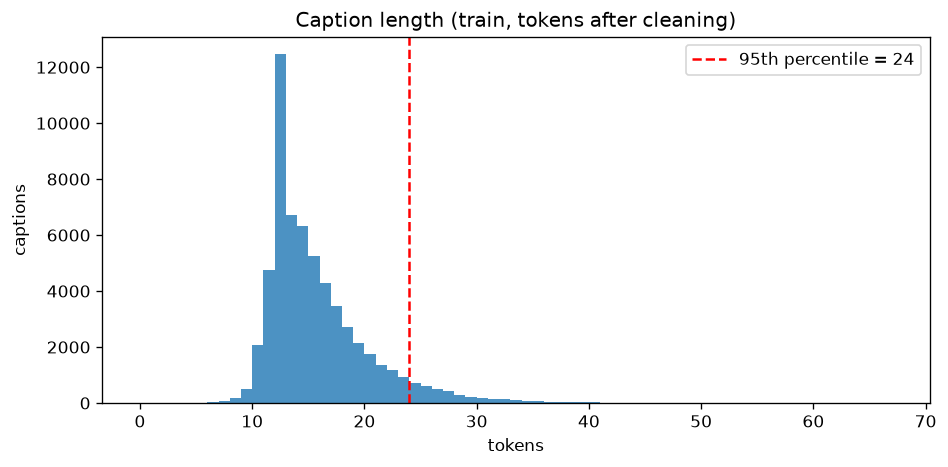

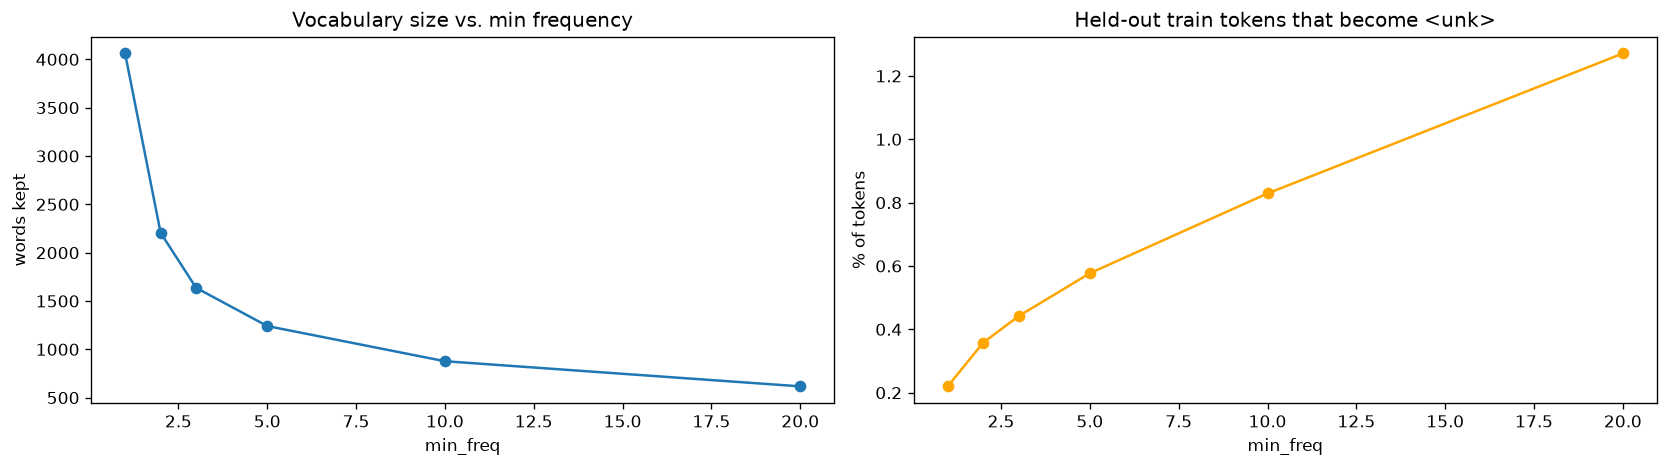

,min_freq,vocab_size,train_token_coverage_%,heldout_unk_token_rate_%
0,1,4061,100.000,0.220
1,2,2205,99.797,0.358
2,3,1636,99.673,0.442
3,5,1241,99.525,0.577
4,10,877,99.259,0.829
5,20,617,98.876,1.271


In [6]:
display(Image(OUT / "figures/05_caption_lengths.png", width=650))
display(Image(OUT / "figures/05_vocab_threshold.png", width=900))
pd.DataFrame(summary["captions"]["vocab_by_min_freq"])

## 6. Augmentation: how big is the bird, and what does cropping keep?

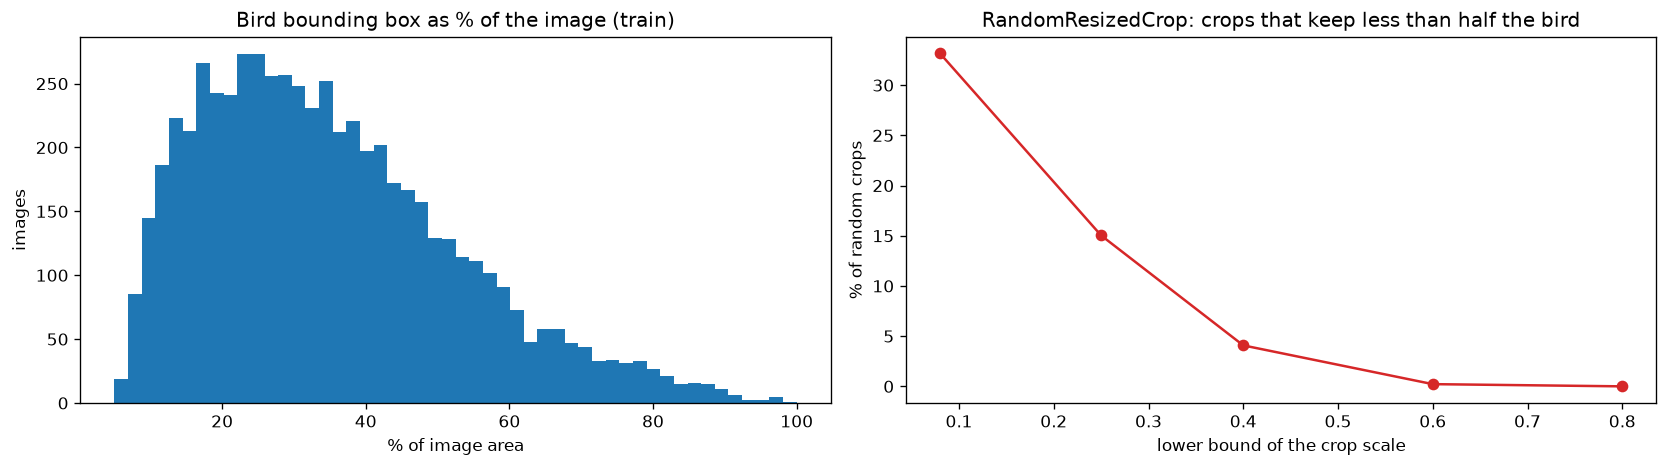

,scale_min,mean_bird_visible_%,%_crops_with_less_than_half_the_bird
0,0.08,64.1,33.16
1,0.25,75.7,15.03
2,0.40,84.1,4.08
3,0.60,93.3,0.22
4,0.80,98.6,0.00


,resize_256_center_crop_224,resize_224_center_crop_224
mean_bird_visible_%,89.00,94.40
%_images_bird_fully_inside,33.47,54.42
%_images_less_than_half_the_bird,0.20,0.03


In [7]:
display(Image(OUT / "figures/06_bird_size_and_crops.png", width=900))
aug = summary.get("augment", {})
display(pd.DataFrame(aug.get("random_resized_crop_by_scale_min", [])))
pd.DataFrame(aug.get("center_crop", {}))

Visual comparison: [proposed](../outputs/eda/figures/06_augmentation_proposed.png) and
[rejected](../outputs/eda/figures/06_augmentation_rejected.png) augmentations.

## Extra exploration 1: do captions follow the colors in the images?

If captions describe what is in the photo, species whose photos are more colorful should get more vivid color words.
This checks that link per class, on train only. Vivid means chromatic: black, white, gray and brown are left out.

  using cached outputs\eda\tables\image_stats.csv


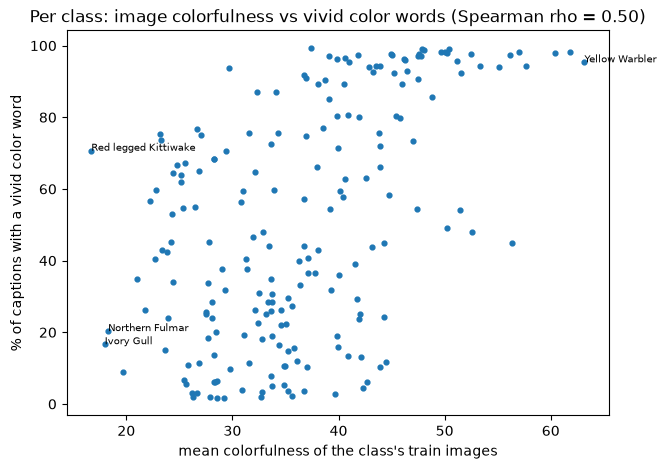

In [8]:
VIVID = {"red", "orange", "yellow", "green", "blue", "purple", "pink", "crimson", "scarlet", "golden", "gold"}
caps, _ = ctx.captions
train_caps = caps[caps.split == "train"]
vivid_share = train_caps.groupby("label_name").clean.apply(
    lambda s: 100 * s.str.split().map(lambda t: bool(VIVID & set(t))).mean())
images = ctx.image_df
colorfulness = images[(images.split == "train") & (images.error == "")].groupby("label_name").colorfulness.mean()
per_class = pd.DataFrame({"colorfulness": colorfulness, "vivid_caption_%": vivid_share}).dropna()
rho = per_class.corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_class.colorfulness, per_class["vivid_caption_%"], s=12)
for name in [per_class.colorfulness.idxmax(), *per_class.nsmallest(3, "colorfulness").index]:
    ax.annotate(name, (per_class.colorfulness[name], per_class["vivid_caption_%"][name]), fontsize=7)
ax.set(title=f"Per class: image colorfulness vs vivid color words (Spearman rho = {rho:.2f})",
       xlabel="mean colorfulness of the class's train images", ylabel="% of captions with a vivid color word")
plt.show()

**Result:** a moderate positive correlation (Spearman rho about 0.5): species with more colorful photos get more
vivid color words, so caption colors are grounded in the pixels. Hue jitter would therefore make captions wrong, and
colorization learns the same color cues the captions use.

The scatter is wide because colorfulness averages over the whole photo, background included. The Red legged Kittiwake
shows it best: its photos are among the dullest, yet about 70% of its captions name a vivid color, because people
mention its small red legs. This is the same lesson as the grayscale check in Step 3: a small colored patch matters.

## Extra exploration 2: which species are smallest in the frame?

Uses the official bounding boxes (`--fetch-cub-meta`). Species that fill little of the frame are the ones most at risk
from aggressive cropping, and the ones where Grad-CAM should be checked for attention on the background.

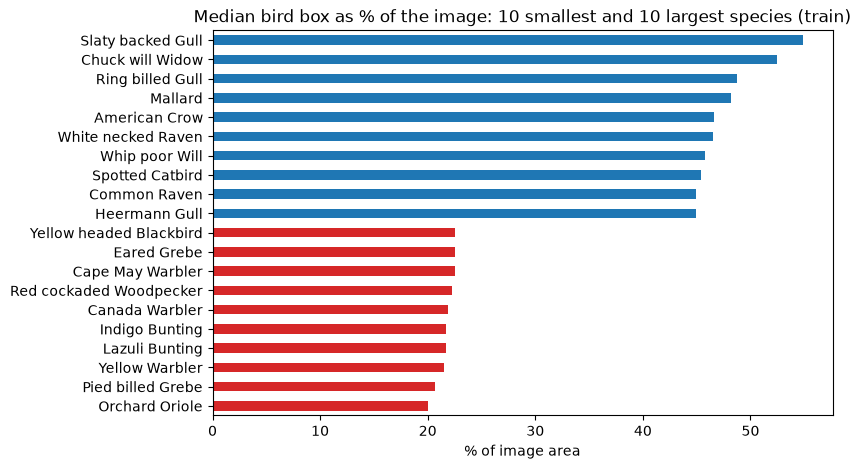

In [9]:
official_meta = load_official_metadata(ctx.cub_meta)
if official_meta is None:
    print("official CUB metadata not found: run python -m src.data.eda --fetch-cub-meta")
else:
    boxed = images[images.split == "train"].merge(official_meta, on="file_name")
    boxed["bird_%"] = 100 * boxed.bbox_w * boxed.bbox_h / (boxed.width * boxed.height)
    by_class = boxed.groupby("label_name")["bird_%"].median().sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    pd.concat([by_class.head(10), by_class.tail(10)]).plot.barh(ax=ax, color=["tab:red"] * 10 + ["tab:blue"] * 10)
    ax.set(title="Median bird box as % of the image: 10 smallest and 10 largest species (train)",
           xlabel="% of image area", ylabel="")
    plt.show()

**Result:** even the species that appear smallest (orioles, warblers, grebes) still fill a median of about 20% of
the image, while gulls and nightjars fill about 50%. With a crop scale of at least 0.6, a crop keeps most of the bird
even for the small species, which matches the crop analysis in Step 6.